In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.optimize import bisect
from scipy.interpolate import griddata
from scipy.stats import norm
from scipy.integrate import quad


class StaircaseInference:
    def __init__(self, mu=0.5, sig_level=0.05,
                 xb_init=100, xa=25, prob_b=0.5, xb_step=25,
                 sigma=0.5, lambd=1.0, 
                 gamma_diff = 0.9, ratio_high_gamma = 0.5, 
                 dist_type = 'binomial'):
        self.mu = mu
        self.lambd = lambd
        self.alpha = sig_level
        self.dist_type = dist_type
        self.xb_init = xb_init
        self.xb_up = xb_init + xb_step
        self.xb_down = xb_init - xb_step
        self.xa = xa
        self.prob_b = prob_b
        if dist_type == 'johnsonSB':
            self.sigma = sigma
        elif dist_type == 'binomial':
            self.gamma_low = self.mu - gamma_diff * ratio_high_gamma
            self.gamma_high = self.gamma_low + gamma_diff
            self.ratio_high_gamma = ratio_high_gamma
            if self.gamma_low <= 0 or self.gamma_high >= 1:
                raise ValueError("Invalid gamma range.")
            
    def _p_choice_a(self, gamma, lambd, xb):
        # Utility u(x) = x^(1-gamma)
        ev_b = self.prob_b * (xb**(1 - gamma))
        u_a = self.xa**(1 - gamma)
        return 1 / (1 + np.exp((ev_b - u_a) / lambd))


    def get_stats_johnsonSB(self, n, sigma, lambd):
        """
        Calculate probability difference (Delta P) and Standard Error (SE)

        Johnson SB distribution:
        gamma = 1 / (1 + exp(theta)) where theta ~ N(mu, sigma^2)
        """
        def _p_choice_a_johnsonSB(theta, lambd, xb):
            gamma = 1 / (1 + np.exp(theta))
            return self._p_choice_a(gamma, lambd, xb)
         # Integration for Population Expectations
        def integrand_a1(t): 
            return _p_choice_a_johnsonSB(t, lambd, self.xb_init) * norm.pdf(t, self.mu, sigma)
        def integrand_a1a2(t):
            p1 = _p_choice_a_johnsonSB(t, lambd, self.xb_up)
            p2 = _p_choice_a_johnsonSB(t, lambd, self.xb_up)
            return p2 * p1 * norm.pdf(t, self.mu, sigma)
        def integrand_b1a2(t):
            p1 = _p_choice_a_johnsonSB(t, lambd, self.xb_down)
            p2 = _p_choice_a_johnsonSB(t, lambd, self.xb_down)
            return p2 * (1 - p1) * norm.pdf(t, self.mu, sigma)

        # Limits for integration
        low, high = self.mu - 6*sigma, self.mu + 6*sigma
        ea1, _ = quad(integrand_a1, low, high)
        ea1a2, _ = quad(integrand_a1a2, low, high)
        eb1a2, _ = quad(integrand_b1a2, low, high)

        p_a2_a1 = ea1a2 / ea1
        p_a2_b1 = eb1a2 / (1 - ea1)
        
        delta_p = p_a2_a1 - p_a2_b1
        
        # Standard Error calculation based on group sizes n1 and n2
        n1 = n * ea1      # Expected number of people choosing A in R1
        n2 = n * (1-ea1)  # Expected number of people choosing B in R1
        se = np.sqrt((p_a2_a1*(1-p_a2_a1)/n1) + (p_a2_b1*(1-p_a2_b1)/n2))
        
        return delta_p, se
    

    def get_stats_bionomial(self, n, gamma_low, gamma_high, ratio_gamma_high, lambd):
        """
        Calculate probability difference (Delta P) and Standard Error (SE)
        
        gamma follows a binomial distribution
        """
        def p_probs(theta):
            p1 = self._p_choice_a(theta, lambd, self.xb_init)
            p2a = self._p_choice_a(theta, lambd, self.xb_up) # A1 branch: B reward increases
            p2b = self._p_choice_a(theta, lambd, self.xb_down)  # B1 branch: B reward decreases
            return p1, p2a, p2b
        
        p1_h, p2a_h, p2b_h = p_probs(gamma_high)
        p1_l, p2a_l, p2b_l = p_probs(gamma_low)

        # expected choice probability of option A in the first round
        e_p1 = ratio_gamma_high * p1_h + (1 - ratio_gamma_high) * p1_l

        # conditional probability P(A2 | A1)
        p_a2_a1 = (ratio_gamma_high * p2a_h * p1_h + (1 - ratio_gamma_high) * p2a_l * p1_l) / e_p1

        # conditional probability P(A2 | B1)
        p_a2_b1 = (ratio_gamma_high * p2b_h * (1 - p1_h) + (1 - ratio_gamma_high) * p2b_l * (1 - p1_l)) / (1 - e_p1)

        delta_p = p_a2_a1 - p_a2_b1

        # SE
        n1 = n * e_p1
        n2 = n * (1 - e_p1)
        se = np.sqrt((p_a2_a1*(1-p_a2_a1)/n1) + (p_a2_b1*(1-p_a2_b1)/n2))

        return delta_p, se


    def z_statistic(self, n, sigma=None, lambd=None, 
                    gamma_low=None, gamma_high=None, ratio_gamma_high=None):
        """Returns the Wald Statistic (Delta P / SE)."""
        if self.dist_type == 'binomial':
            gamma_h = self.gamma_high if gamma_high is not None else self.gamma_high
            gamma_l = self.gamma_low if gamma_low is not None else self.gamma_low
            ratio_h = self.ratio_high_gamma if ratio_gamma_high is not None else self.ratio_high_gamma
            l = lambd if lambd is not None else self.lambd
            dp, se = self.get_stats_bionomial(n, gamma_l, gamma_h, ratio_h, l)

        elif self.dist_type == 'johnsonSB':
            s = sigma if sigma is not None else self.sigma
            l = lambd if lambd is not None else self.lambd
            dp, se = self.get_stats_johnsonSB(n, s, l)
            
        return dp / se

    def reject_prob(self, n, sigma=None, lambd=None):
        """Power: Prob(Z > z_alpha)"""
        z_score = self.z_statistic(n, sigma, lambd)
        z_crit = norm.ppf(1 - self.alpha)
        return 1 - norm.cdf(z_crit - z_score)



In [166]:
def objective(lambd):
    model = StaircaseInference(gamma_diff=0.5, ratio_high_gamma=0.5, 
                               lambd=lambd, dist_type='binomial')
    return model.reject_prob(n=1000) - 0.05

# solve for lambda where null-rejection probability is 0.05
# when lambda > lambda_crit, the null-rejection probability is < 0.05
lambd_crit = bisect(objective, 0.01, 10.0)
lambd_crit

C:\Users\zarkwang\AppData\Local\Temp\ipykernel_2360\1386537286.py:39: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp((ev_b - u_a) / lambd))


2.9027449157819825

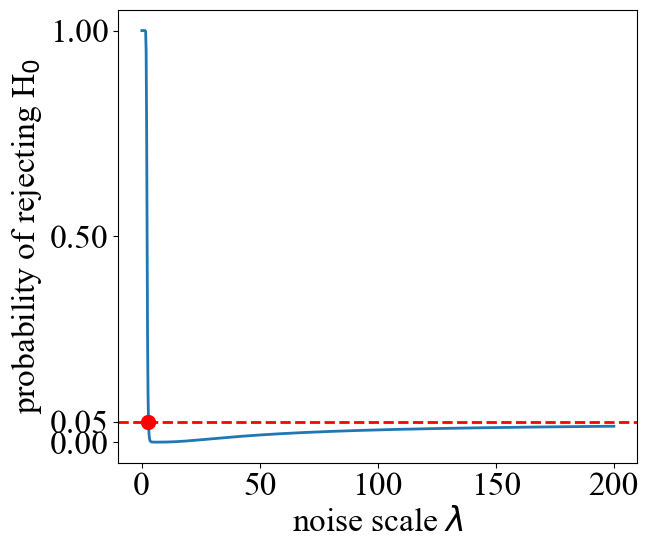

In [167]:
lambd_vals = np.linspace(0.1, 200, 1000) 
model = StaircaseInference(gamma_diff=0.5, ratio_high_gamma=0.5, lambd=lambd_vals, dist_type='binomial')
prob_vals = model.reject_prob(n=1000)

plt.figure(figsize=(7, 6))
plt.plot(lambd_vals, prob_vals, linewidth=2)
plt.axhline(y=0.05, color='r', linestyle='--', linewidth=2)
plt.plot(lambd_crit, 0.05, 'ro', markersize=10)
plt.xlabel(r'noise scale $\lambda$')
plt.ylabel(r'probability of rejecting H$_0$')
plt.yticks([0, 0.05, 0.5, 1])
plt.tight_layout()
plt.show()


In [158]:
def objective(lambd):
    model = StaircaseInference(sigma=2.5, lambd=lambd, dist_type='johnsonSB') 
    return model.reject_prob(n=1000) - 0.05

# solve for lambda where null-rejection probability is 0.05
# when lambda > lambda_crit, the null-rejection probability is < 0.05
lambd_crit = bisect(objective, 0.01, 100.0)
lambd_crit

C:\Users\zarkwang\AppData\Local\Temp\ipykernel_2360\1386537286.py:39: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp((ev_b - u_a) / lambd))


12.926321322919781

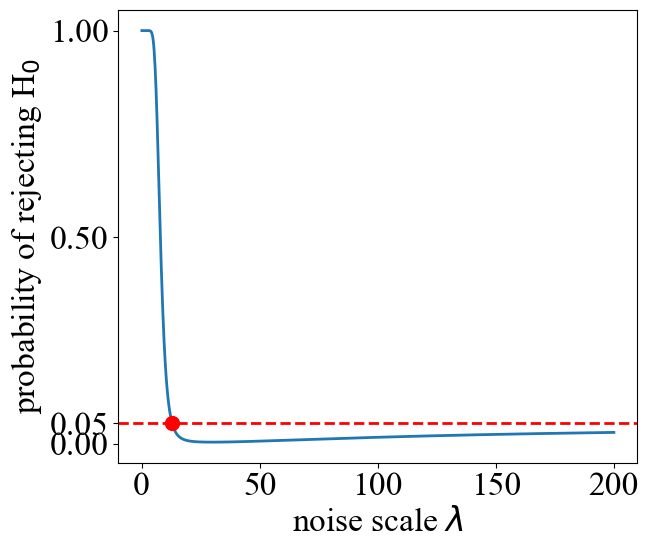

In [159]:
lambd_vals = np.linspace(0.1, 200, 1000)
prob_vals = []
for i in range(len(lambd_vals)):
    model = StaircaseInference(sigma=2.5, lambd=lambd_vals[i], dist_type='johnsonSB') 
    prob_vals.append(model.reject_prob(n=1000))

plt.figure(figsize=(7, 6))
plt.plot(lambd_vals, prob_vals, linewidth=2)
plt.axhline(y=0.05, color='r', linestyle='--', linewidth=2)
plt.plot(lambd_crit, 0.05, 'ro', markersize=10)
plt.xlabel(r'noise scale $\lambda$')
plt.ylabel(r'probability of rejecting H$_0$')
plt.yticks([0, 0.05, 0.5, 1])
plt.tight_layout()
plt.show()

In [53]:
# Create grid of values
lambda_vals = np.linspace(0.4, 2.5, 50)  
gamma_diff_vals = np.linspace(0.2, 0.5, 50)
ratio_h_vals = np.array([0.5, 0.3, 0.1])

# L, S = np.meshgrid(lambda_vals, sigma_vals, indexing='ij')
# Z = np.zeros_like(L, dtype=float)

# Calculate z-statistic for all combinations
data = []
for lambd in lambda_vals:
    for gamma_diff in gamma_diff_vals:
        for ratio_h in ratio_h_vals:
            model = StaircaseInference(lambd=lambd, gamma_diff=gamma_diff, ratio_high_gamma=ratio_h,
                                       dist_type='binomial')
            z = model.z_statistic(n=1000)
            data.append({
                'lambda': lambd,
                'gamma_diff': gamma_diff,
                'ratio_high': ratio_h,
                'z_statistic': z
        })

# Create DataFrame
df = pd.DataFrame(data)


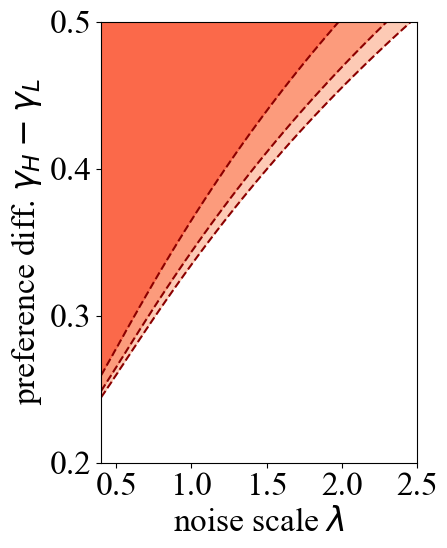

In [54]:
# Create a grid for contour plotting
lambda_grid, gamma_grid = np.meshgrid(lambda_vals, gamma_diff_vals)

target_ratio_h = ratio_h_vals[0]
target_rejection_probs = [0.3, 0.5, 0.9]
sorted_probs = sorted(target_rejection_probs)

# Map prob to color: we want lighter for lower prob, darker for higher prob
colors_sorted = plt.cm.Reds(np.linspace(0.2, 0.5, len(sorted_probs)))

# Interpolate z values onto the grid
z_grid = griddata(
    (df[df['ratio_high']==target_ratio_h]['lambda'], df[df['ratio_high']==target_ratio_h]['gamma_diff']),
    df[df['ratio_high']==target_ratio_h]['z_statistic'],
    (lambda_grid, gamma_grid),
    method='linear'
)


# Plot
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 24
plt.figure(figsize=(5,6))

for i, prob in enumerate(sorted_probs):
    z_threshold = norm.ppf(prob) + norm.ppf(1 - model.alpha)
    # contourf with color from the list
    plt.contourf(lambda_grid, gamma_grid, z_grid,
                 levels=[z_threshold, np.inf],
                 colors=[colors_sorted[i]],
                 alpha=1.0)
    # Contour line at threshold
    plt.contour(lambda_grid, gamma_grid, z_grid, levels=[z_threshold],
                colors='darkred', linewidths=1.5, linestyles='--')


plt.gca().set_yticks([0.2, 0.3, 0.4, 0.5])
plt.gca().set_xticks([0.5, 1.0, 1.5, 2.0, 2.5])
plt.xlabel(r'noise scale $\lambda$')
plt.ylabel(r'preference diff. $\gamma_H - \gamma_L$')
plt.tight_layout()
plt.show()

In [47]:
# Create grid of values
lambda_vals = np.linspace(0.4, 4.5, 50)  
sigma_vals = np.linspace(0.5, 2.5, 50)

# L, S = np.meshgrid(lambda_vals, sigma_vals, indexing='ij')
# Z = np.zeros_like(L, dtype=float)

# Calculate z-statistic for all combinations
data = []
for lambd in lambda_vals:
    for sigma in sigma_vals:
        model = StaircaseInference(mu=0.5, lambd=lambd, sigma=sigma,dist_type='johnsonSB')
        z = model.z_statistic(n=1000)
        data.append({
            'lambda': lambd,
            'sigma': sigma,
            'z_statistic': z
        })

# Create DataFrame
df = pd.DataFrame(data)


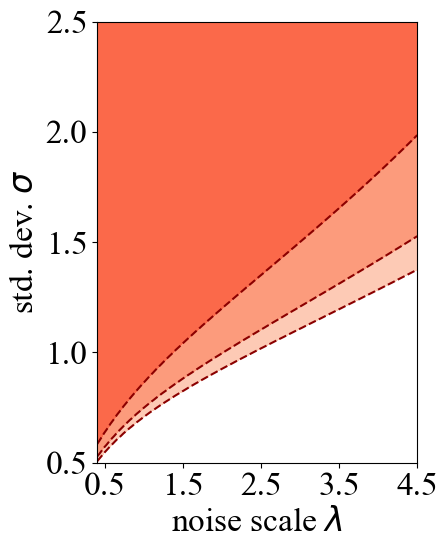

In [48]:
# Create a grid for contour plotting
lambda_grid, sigma_grid = np.meshgrid(lambda_vals, sigma_vals)

target_rejection_probs = [0.3,0.5,0.9]
sorted_probs = sorted(target_rejection_probs)

# Map prob to color: we want lighter for lower prob, darker for higher prob
colors_sorted = plt.cm.Reds(np.linspace(0.2, 0.5, len(sorted_probs)))

# Interpolate z values onto the grid
z_grid = griddata(
    (df['lambda'], df['sigma']),
    df['z_statistic'],
    (lambda_grid, sigma_grid),
    method='linear'
)


# Plot
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 24
plt.figure(figsize=(5,6))

for i, prob in enumerate(sorted_probs):
    z_threshold = norm.ppf(prob) + norm.ppf(1 - model.alpha)
    # contourf with color from the list
    plt.contourf(lambda_grid, sigma_grid, z_grid,
                 levels=[z_threshold, np.inf],
                 colors=[colors_sorted[i]],
                 alpha=1.0)
    # Contour line at threshold
    plt.contour(lambda_grid, sigma_grid, z_grid, levels=[z_threshold],
                colors='darkred', linewidths=1.5, linestyles='--')


plt.gca().set_xticks([0.5, 1.5, 2.5, 3.5, 4.5])
plt.xlabel(r'noise scale $\lambda$')
plt.ylabel(r'std. dev. $\sigma$')
plt.tight_layout()
plt.show()

<>:4: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:4: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
C:\Users\zarkwang\AppData\Local\Temp\ipykernel_23316\3009045058.py:4: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
  legend_patches = [mpatches.Patch(color=color_dict[prob], label=f'$\geq${prob}') for prob in target_rejection_probs]


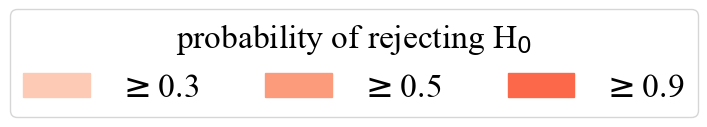

In [42]:
# Create legend patches using original order (if you want legend in original order)
# We need to map each prob to its color from the sorted mapping.
color_dict = {prob: colors_sorted[i] for i, prob in enumerate(sorted_probs)}
legend_patches = [mpatches.Patch(color=color_dict[prob], label=f'$\geq${prob}') for prob in target_rejection_probs]


fig, ax = plt.subplots(figsize=(5, 1.2))  
ax.axis('off') 
ax.legend(handles=legend_patches,
          title='probability of rejecting H$_0$',
          ncol=len(target_rejection_probs),  
          loc='center',                     
          frameon=True)                    


plt.tight_layout()